# Module 2 - Partie 5 : Évaluation

## Objectif

Mesurer ce que vaut la régression logistique de la partie 4, avec un protocole où le jeu de test ne sert qu'une fois.

L'ordre des étapes est fixé à l'avance :

1. validation croisée temporelle sur les périodes d'entraînement et de validation ;
2. choix du seuil de décision sur la validation, à partir du critère métier du data canvas ;
3. gel du modèle et du seuil ;
4. évaluation sur le test, une seule fois ;
5. intervalles de confiance par bootstrap sur les résultats du test.

Rien de ce qui est observé sur le test ne sert à revenir sur le modèle ou sur le seuil.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

GRAINE = 42
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})

print("Bibliothèques importées avec succès.")

Bibliothèques importées avec succès.


## 1. Données, découpage et pipelines de la partie 4

Le découpage et les pipelines sont repris à l'identique de `04_Decoupage_Pipeline.ipynb` : frontières aux quantiles 60 % et 80 % de `step`, six variables connues au moment de la transaction, même prétraitement, mêmes modèles.

Le jeu de test est mis de côté dans cette cellule. Il n'est relu qu'à la section 5.

In [2]:
df = pd.read_parquet(Path("../paysim_echantillon.parquet"))

borne_train = int(df["step"].quantile(0.60))
borne_validation = int(df["step"].quantile(0.80))

df_train = df[df["step"] <= borne_train].copy()
df_val = df[(df["step"] > borne_train) & (df["step"] <= borne_validation)].copy()
df_test = df[df["step"] > borne_validation].copy()

assert df_train["step"].max() < df_val["step"].min()
assert df_val["step"].max() < df_test["step"].min()
assert len(df_train) + len(df_val) + len(df_test) == len(df)

variables_numeriques = [
    "amount",
    "oldbalanceOrg",
    "oldbalanceDest",
    "nb_tx_orig_avant",
    "nb_recu_dest_avant",
]
variables_categorielles = ["type"]
variables = variables_categorielles + variables_numeriques
cible = "isFraud"

print("Entraînement : steps 1 à", borne_train, "-", len(df_train), "transactions")
print("Validation   : steps", borne_train + 1, "à", borne_validation, "-", len(df_val), "transactions")
print("Test         : steps", borne_validation + 1, "à", df["step"].max(), "-", len(df_test), "transactions (mis de côté)")

Entraînement : steps 1 à 281 - 335288 transactions
Validation   : steps 282 à 354 - 109304 transactions
Test         : steps 355 à 743 - 110516 transactions (mis de côté)


In [3]:
preprocesseur = ColumnTransformer(transformers=[
    ("numerique", Pipeline(steps=[
        ("imputation", SimpleImputer(strategy="median")),
        ("standardisation", StandardScaler()),
    ]), variables_numeriques),
    ("categoriel", Pipeline(steps=[
        ("imputation", SimpleImputer(strategy="most_frequent")),
        ("encodage", OneHotEncoder(handle_unknown="ignore")),
    ]), variables_categorielles),
])


def creer_pipeline_naif():
    return Pipeline(steps=[
        ("pretraitement", clone(preprocesseur)),
        ("modele", DummyClassifier(strategy="prior")),
    ])


def creer_pipeline_logistique():
    return Pipeline(steps=[
        ("pretraitement", clone(preprocesseur)),
        ("modele", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=GRAINE,
        )),
    ])


print("Pipelines non ajustés définis.")

Pipelines non ajustés définis.


## 2. Métriques adaptées au déséquilibre

Avec 0,29 % de fraudes, l'accuracy ne dit rien : le modèle naïf dépasse 99 % sans signaler une seule fraude. Les métriques retenues regardent la classe rare.

| Métrique | Ce qu'elle mesure | Dépend du seuil ? |
| --- | --- | --- |
| PR-AUC (average precision) | Qualité du classement des fraudes en tête des scores. Pour un modèle sans information, elle vaut le taux de fraude. | Non |
| Rappel | Part des fraudes signalées. | Oui |
| Précision | Part des alertes qui sont de vraies fraudes. | Oui |
| Taux de faux positifs | Part des transactions légitimes bloquées à tort. C'est le critère du data canvas. | Oui |
| Montant fraudé intercepté | Rappel pondéré par `amount` : le besoin métier porte sur le montant fraudé, pas sur le nombre de fraudes. | Oui |

L'AUC ROC est affichée à titre indicatif dans la validation croisée. Elle est peu lisible ici : avec autant de transactions légitimes, un taux de faux positifs qui paraît faible représente déjà des milliers d'alertes.

Règle de décision : une transaction est signalée quand son score dépasse strictement le seuil.

In [4]:
def mesures(y, score, montant, seuil):
    """Métriques d'un modèle pour un seuil donné (alerte si score > seuil)."""
    y = np.asarray(y)
    score = np.asarray(score)
    montant = np.asarray(montant)
    fraude = y == 1
    alerte = score > seuil
    vrais_positifs = int((alerte & fraude).sum())
    faux_positifs = int((alerte & ~fraude).sum())
    return {
        "PR-AUC": average_precision_score(y, score),
        "Rappel": vrais_positifs / fraude.sum(),
        "Précision": vrais_positifs / max(vrais_positifs + faux_positifs, 1),
        "Taux de faux positifs": faux_positifs / (~fraude).sum(),
        "Montant fraudé intercepté": montant[alerte & fraude].sum() / montant[fraude].sum(),
    }


def seuil_sous_contrainte(y, score, taux_max):
    """Plus petit seuil dont le taux de faux positifs ne dépasse pas taux_max."""
    scores_legitimes = np.asarray(score)[np.asarray(y) == 0]
    return float(np.quantile(scores_legitimes, 1 - taux_max, method="higher"))


def en_pourcentage(tableau, colonnes):
    affichage = tableau.copy()
    for colonne in colonnes:
        affichage[colonne] = affichage[colonne].map(lambda valeur: f"{valeur:.2%}")
    return affichage


# Critère du data canvas : moins de 1 % de transactions légitimes bloquées à tort.
TAUX_FAUX_POSITIFS_MAX = 0.01

## 3. Validation croisée temporelle

Une validation croisée classique mélange les périodes : un modèle y serait entraîné sur des transactions postérieures à celles qu'il doit prédire. On utilise donc une fenêtre croissante. La période de développement (entraînement + validation, steps 1 à 354) est coupée en quatre blocs chronologiques aux quantiles 20 %, 40 % et 60 % de `step`. Chaque pli s'entraîne sur les blocs passés et prédit le bloc suivant.

Le troisième pli est exactement le découpage entraînement / validation de la partie 4. Les frontières tombent entre deux steps, donc aucun step n'est partagé entre l'entraînement et la validation d'un pli.

Le test n'intervient dans aucun pli.

In [5]:
df_dev = df[df["step"] <= borne_validation]
bornes_cv = [int(df["step"].quantile(q)) for q in (0.20, 0.40)] + [borne_train, borne_validation]

lignes_cv = []
for numero in range(1, len(bornes_cv)):
    debut_val, fin_val = bornes_cv[numero - 1], bornes_cv[numero]
    pli_train = df_dev[df_dev["step"] <= debut_val]
    pli_val = df_dev[(df_dev["step"] > debut_val) & (df_dev["step"] <= fin_val)]

    naif = creer_pipeline_naif().fit(pli_train[variables], pli_train[cible])
    logistique = creer_pipeline_logistique().fit(pli_train[variables], pli_train[cible])
    score_naif = naif.predict_proba(pli_val[variables])[:, 1]
    score_logistique = logistique.predict_proba(pli_val[variables])[:, 1]

    seuil_pli = seuil_sous_contrainte(pli_val[cible], score_logistique, TAUX_FAUX_POSITIFS_MAX)
    mesures_pli = mesures(pli_val[cible], score_logistique, pli_val["amount"], seuil_pli)

    lignes_cv.append({
        "Pli": numero,
        "Entraînement (steps)": f"1 à {debut_val}",
        "Validation (steps)": f"{debut_val + 1} à {fin_val}",
        "Fraudes en validation": int(pli_val[cible].sum()),
        "PR-AUC naïf": average_precision_score(pli_val[cible], score_naif),
        "PR-AUC logistique": mesures_pli["PR-AUC"],
        "AUC ROC logistique": roc_auc_score(pli_val[cible], score_logistique),
        "Seuil à 1 % de faux positifs": seuil_pli,
        "Rappel à ce seuil": mesures_pli["Rappel"],
    })

tableau_cv = pd.DataFrame(lignes_cv).set_index("Pli")
colonnes_cv = ["PR-AUC naïf", "PR-AUC logistique", "AUC ROC logistique",
               "Seuil à 1 % de faux positifs", "Rappel à ce seuil"]
display(tableau_cv.round(4))

resume_cv = tableau_cv[colonnes_cv].agg(["mean", "std"]).rename(
    index={"mean": "Moyenne", "std": "Écart-type"}
)
display(resume_cv.round(4))

,Entraînement (steps),Validation (steps),Fraudes en validation,PR-AUC naïf,PR-AUC logistique,AUC ROC logistique,Seuil à 1 % de faux positifs,Rappel à ce seuil
Pli,,,,,,,,
1,1 à 134,135 à 205,146,0.0013,0.1506,0.9471,0.9597,0.3356
2,1 à 205,206 à 281,162,0.0015,0.2233,0.9486,0.9780,0.4383
3,1 à 281,282 à 354,136,0.0012,0.1258,0.9509,0.9806,0.3603


,PR-AUC naïf,PR-AUC logistique,AUC ROC logistique,Seuil à 1 % de faux positifs,Rappel à ce seuil
Moyenne,0.0013,0.1666,0.9488,0.9728,0.3781
Écart-type,0.0001,0.0507,0.0019,0.0114,0.0536


La régression logistique bat le modèle naïf sur les trois plis : PR-AUC moyenne de 0,167 contre 0,001, qui est simplement le taux de fraude. L'AUC ROC reste autour de 0,95 d'un pli à l'autre.

La PR-AUC bouge davantage, de 0,13 à 0,22. Chaque pli ne contient que 136 à 162 fraudes, donc quelques fraudes mieux ou moins bien classées suffisent à la déplacer. À 1 % de faux positifs, le rappel va de 34 % à 44 %.

Le seuil qui donne 1 % de faux positifs monte avec la taille de l'entraînement : 0,960, puis 0,978, puis 0,981. Un seuil ne vaut donc que pour le modèle sur lequel il a été réglé. On fixe le seuil sur le pli 3 et on garde ce même modèle pour le test, sans le réentraîner sur la validation.

## 4. Choix du seuil de décision

Le seuil par défaut de 0,5 n'a pas de justification métier. Avec `class_weight="balanced"`, les scores ne sont pas des probabilités de fraude calibrées : 0,5 signale beaucoup trop de transactions.

Le data canvas fixe un objectif : réduire le montant fraudé en gardant les faux positifs sous 1 %. On le traduit ainsi : parmi les seuils dont le taux de faux positifs reste sous 1 % des transactions légitimes, on prend le plus bas, c'est-à-dire celui qui laisse passer le moins de fraudes.

Le seuil est calculé sur la validation, avec le modèle entraîné sur l'entraînement seul (le pli 3 ci-dessus). Le test n'est pas consulté.

In [6]:
pipeline_naif = creer_pipeline_naif().fit(df_train[variables], df_train[cible])
pipeline_logistique = creer_pipeline_logistique().fit(df_train[variables], df_train[cible])

score_val = pipeline_logistique.predict_proba(df_val[variables])[:, 1]

SEUIL = seuil_sous_contrainte(df_val[cible], score_val, TAUX_FAUX_POSITIFS_MAX)
print(f"Seuil retenu : {SEUIL:.4f}")

lignes_seuil = []
for nom, seuil in [("0,5 (défaut)", 0.5), ("0,9", 0.9), ("Seuil retenu", SEUIL), ("0,999", 0.999)]:
    ligne = {"Seuil": nom, "Transactions signalées": int((score_val > seuil).sum())}
    ligne.update(mesures(df_val[cible], score_val, df_val["amount"], seuil))
    lignes_seuil.append(ligne)

tableau_seuil = pd.DataFrame(lignes_seuil).set_index("Seuil").drop(columns="PR-AUC")
display(en_pourcentage(tableau_seuil, ["Rappel", "Précision", "Taux de faux positifs",
                                       "Montant fraudé intercepté"]))

Seuil retenu : 0.9806


,Transactions signalées,Rappel,Précision,Taux de faux positifs,Montant fraudé intercepté
Seuil,,,,,
"0,5 (défaut)",8718,83.82%,1.31%,7.88%,99.17%
"0,9",2380,48.53%,2.77%,2.12%,95.27%
Seuil retenu,1140,36.03%,4.30%,1.00%,90.20%
"0,999",309,23.53%,10.36%,0.25%,81.90%


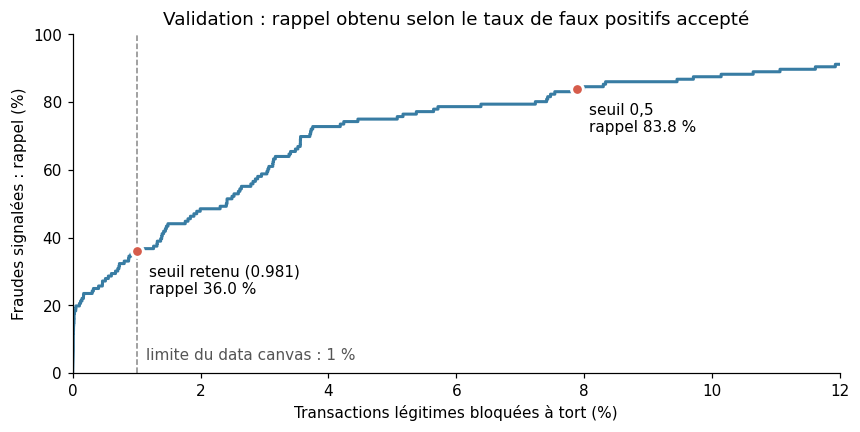

In [7]:
taux_fp, rappel, _ = roc_curve(df_val[cible], score_val)
point_defaut = mesures(df_val[cible], score_val, df_val["amount"], 0.5)
point_retenu = mesures(df_val[cible], score_val, df_val["amount"], SEUIL)

fig, ax = plt.subplots()
ax.plot(100 * taux_fp, 100 * rappel, color="#387ca3", linewidth=2)
ax.axvline(100 * TAUX_FAUX_POSITIFS_MAX, color="#888888", linestyle="--", linewidth=1)
ax.text(100 * TAUX_FAUX_POSITIFS_MAX + 0.15, 4, "limite du data canvas : 1 %", color="#555555")
for point, nom in [(point_retenu, f"seuil retenu ({SEUIL:.3f})"), (point_defaut, "seuil 0,5")]:
    x, y = 100 * point["Taux de faux positifs"], 100 * point["Rappel"]
    ax.scatter([x], [y], s=60, color="#d65c4b", edgecolor="white", linewidth=2, zorder=3)
    ax.annotate(f"{nom}\nrappel {y:.1f} %", (x, y), xytext=(8, -28), textcoords="offset points")
ax.set_xlim(0, 12)
ax.set_ylim(0, 100)
ax.set_xlabel("Transactions légitimes bloquées à tort (%)")
ax.set_ylabel("Fraudes signalées : rappel (%)")
ax.set_title("Validation : rappel obtenu selon le taux de faux positifs accepté")
plt.show()

Seuil retenu : 0,9806.

Sur la validation, il signale 1 140 transactions au lieu de 8 718 au seuil 0,5, et le taux de faux positifs passe de 7,88 % à 1,00 %. Le rappel tombe de 83,8 % à 36,0 % : c'est le prix de la contrainte du data canvas.

En montant, la perte est bien plus faible : 90,2 % du montant fraudé reste intercepté, contre 99,2 % à 0,5. Les fraudes qui échappent au modèle sont surtout de petits montants.

La précision reste basse, 4,3 %. Avec 0,12 % de fraudes dans la validation, 1 % de faux positifs représente déjà 1 091 fausses alertes, pour 49 fraudes signalées.

Le seuil est maintenant figé.

## 5. Évaluation sur le test, une seule fois

Le modèle et le seuil sont figés : pipeline de régression logistique ajusté sur l'entraînement, seuil fixé sur la validation. La cellule suivante est la seule du projet qui calcule des scores sur le test. Ils sont stockés une fois, et toutes les métriques et tous les intervalles de confiance sont calculés à partir de ce même vecteur.

In [8]:
# Seul appel aux modèles sur le jeu de test.
y_test = df_test[cible].to_numpy()
montant_test = df_test["amount"].to_numpy()
score_test_naif = pipeline_naif.predict_proba(df_test[variables])[:, 1]
score_test = pipeline_logistique.predict_proba(df_test[variables])[:, 1]

mesures_test = mesures(y_test, score_test, montant_test, SEUIL)
tableau_test = pd.DataFrame([
    {"Modèle": "Modèle naïf", "Transactions signalées": int((score_test_naif > SEUIL).sum()),
     **mesures(y_test, score_test_naif, montant_test, SEUIL)},
    {"Modèle": "Régression logistique", "Transactions signalées": int((score_test > SEUIL).sum()),
     **mesures_test},
]).set_index("Modèle")

print("Transactions en test :", len(y_test), "dont", int(y_test.sum()), "fraudes",
      f"({y_test.mean():.2%})")
display(en_pourcentage(tableau_test, ["PR-AUC", "Rappel", "Précision", "Taux de faux positifs",
                                      "Montant fraudé intercepté"]))

alerte_test = score_test > SEUIL
matrice = pd.crosstab(
    pd.Series(np.where(y_test == 1, "Fraude", "Légitime"), name="Réalité"),
    pd.Series(np.where(alerte_test, "Signalée", "Non signalée"), name="Décision"),
)
display(matrice)

Transactions en test : 110516 dont 843 fraudes (0.76%)


,Transactions signalées,PR-AUC,Rappel,Précision,Taux de faux positifs,Montant fraudé intercepté
Modèle,,,,,,
Modèle naïf,0,0.76%,0.00%,0.00%,0.00%,0.00%
Régression logistique,1490,34.72%,38.55%,21.81%,1.06%,90.57%


Décision,Non signalée,Signalée
Réalité,,
Fraude,518,325
Légitime,108508,1165


## 6. Intervalles de confiance par bootstrap

Les métriques du test reposent sur quelques centaines de fraudes : il faut donner leur incertitude. On retire 1 000 fois, avec remise, autant de transactions que le test en contient, et on recalcule chaque métrique sur chaque tirage. L'intervalle à 95 % va du percentile 2,5 au percentile 97,5.

Le bootstrap rééchantillonne les scores déjà calculés. Le modèle n'est ni réajusté ni réappliqué, et le seuil ne bouge pas.

In [9]:
N_BOOTSTRAP = 1000
rng = np.random.default_rng(GRAINE)
n_test = len(y_test)

tirages = []
for _ in range(N_BOOTSTRAP):
    indices = rng.integers(0, n_test, n_test)
    tirages.append(mesures(y_test[indices], score_test[indices], montant_test[indices], SEUIL))
tirages = pd.DataFrame(tirages)

tableau_ic = pd.DataFrame({
    "Estimation sur le test": pd.Series(mesures_test),
    "IC 95 % - borne basse": tirages.quantile(0.025),
    "IC 95 % - borne haute": tirages.quantile(0.975),
})
display(tableau_ic.map(lambda valeur: f"{valeur:.2%}"))

,Estimation sur le test,IC 95 % - borne basse,IC 95 % - borne haute
PR-AUC,34.72%,31.50%,37.75%
Rappel,38.55%,35.29%,41.95%
Précision,21.81%,19.82%,23.77%
Taux de faux positifs,1.06%,1.00%,1.12%
Montant fraudé intercepté,90.57%,88.74%,92.09%


Sur le test, la régression logistique signale 1 490 transactions et retrouve 325 des 843 fraudes. Le modèle naïf n'en signale aucune.

| Métrique | Test | IC 95 % | Lecture |
| --- | --- | --- | --- |
| PR-AUC | 34,7 % | 31,5 à 37,8 % | Le modèle naïf est à 0,76 %, le taux de fraude du test. |
| Rappel | 38,6 % | 35,3 à 42,0 % | Dans la fourchette de la validation croisée (34 à 44 %). |
| Montant fraudé intercepté | 90,6 % | 88,7 à 92,1 % | Proche de la validation (90,2 %). |
| Taux de faux positifs | 1,06 % | 1,00 à 1,12 % | Un peu au-dessus de la cible de 1 %. |
| Précision | 21,8 % | 19,8 à 23,8 % | À ne pas comparer aux 4,3 % de la validation, voir ci-dessous. |

Deux résultats demandent une précaution de lecture.

Le taux de faux positifs dépasse légèrement la cible. Le seuil donnait 1,00 % sur la validation et donne 1,06 % sur le test, soit 1 165 transactions légitimes bloquées sur 109 673. L'écart est faible, mais l'objectif du data canvas n'est pas tenu au sens strict sur cette période. Le seuil n'est pas corrigé pour autant : le régler sur le test reviendrait à s'en servir une deuxième fois.

La hausse de la précision et de la PR-AUC ne vient pas du modèle. Le taux de fraude est de 0,76 % dans le test contre 0,12 % dans la validation, parce que le volume de transactions s'effondre en fin de simulation alors que le nombre de fraudes reste stable (voir `01_SQL_DuckDB.ipynb`). À rappel et taux de faux positifs presque identiques, la précision monte mécaniquement quand les fraudes sont plus fréquentes. Le rappel, le taux de faux positifs et le montant intercepté ne dépendent pas de ce taux : ce sont eux qui se comparent d'une période à l'autre.

## 7. Conclusion

Au seuil 0,9806, la régression logistique bloque environ 1 % des transactions légitimes, retrouve 39 % des fraudes et intercepte 91 % du montant fraudé (IC 95 % : 88,7 à 92,1 %). Elle fait nettement mieux que le modèle naïf, et les résultats du test confirment ceux de la validation croisée.

Elle reste un modèle de référence. Plus de six fraudes sur dix passent, et près de quatre alertes sur cinq sont fausses, même sur la période où la fraude est la plus fréquente.

Limites :

- Les intervalles bootstrap supposent des transactions indépendantes. Ils mesurent l'incertitude d'échantillonnage sur la période de test, pas la dérive dans le temps, alors que le taux de fraude varie fortement d'une période à l'autre.
- La validation croisée n'a que trois plis, avec 136 à 162 fraudes chacun.
- Le critère de 1 % de faux positifs est l'objectif provisoire du data canvas. Il reste à valider avec le métier, par exemple en chiffrant le coût d'une transaction bloquée à tort face au montant d'une fraude évitée.
- PaySim est un jeu simulé et l'analyse porte sur un échantillon à 20 % des `TRANSFER` et `CASH_OUT`. Ces chiffres ne se transposent pas tels quels à des données réelles.

Le test a servi une fois. Les prochains modèles devront être comparés sur la validation croisée, pas sur ce test.